# Práctica 8 - Predicción del precio de viviendas mediante regresión lineal
**Sistemas de Aprendizaje Automático · Sesión 8**
 
**Dataset:** `viviendas.csv` (500 viviendas sintéticas)  
**Entrega:** `Practica_08_Regresion_Lineal_Apellido_Nombre.ipynb`

## Objetivo
Construir y comparar **dos modelos**: (A) regresión lineal simple con superficie y (B) regresión lineal múltiple con cinco características. Evaluar **solo con validación**. Reservar **test** para la evaluación final en una sesión posterior.

**Instrucciones:** completa las celdas con `TODO`, ejecuta el código y contesta las preguntas en celdas Markdown. No hay soluciones incluidas. Los datos son sintéticos: las estimaciones no representan precios reales de mercado.

## Parte 1 - Exploración del dataset
### Ejercicio 1. Cargar el dataset
Carga `viviendas.csv`, muestra cinco filas, dimensiones y tipos de datos.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# TODO: cargar el archivo viviendas.csv en df
df = pd.read_csv('viviendas.csv')

# TODO: mostrar las primeras 5 filas
print("Primeras 5 filas:")
print(df.head())

# TODO: mostrar dimensiones y tipos de datos
print("\nDimensiones (filas, columnas):", df.shape)
print("\nTipos de datos e información general:")
print(df.info())

Primeras 5 filas:
  vivienda_id  superficie_m2  habitaciones  banos  antiguedad_anos  \
0       V0001            168             4      3               21   
1       V0002             65             3      2               55   
2       V0003             42             2      1               34   
3       V0004            135             5      3               43   
4       V0005             93             5      1               10   

   distancia_centro_km  precio_euros  
0                 17.6        360900  
1                 15.8        105300  
2                  7.6        100800  
3                 15.5        330400  
4                 20.3        183900  

Dimensiones (filas, columnas): (500, 7)

Tipos de datos e información general:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   vivienda_id          500 non-null    str    
 1  

**Responde:** ¿Cuántas viviendas y columnas hay? ¿Cuál es la variable objetivo? ¿Por qué es un problema de regresión?

**Respuesta:** ...

### Ejercicio 2. Exploración estadística
Obtén estadísticas descriptivas y comprueba los valores ausentes.

In [5]:
# TODO: mostrar df.describe()
display(df.describe())

# TODO: contar valores ausentes por columna
display(df.isna().sum())

,superficie_m2,habitaciones,banos,antiguedad_anos,distancia_centro_km,precio_euros
count,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000
mean,112.430000,3.514000,1.724000,29.14800,11.558000,265734.400000
std,42.998918,1.550035,0.687582,18.09378,6.459815,115207.607224
min,38.000000,1.000000,1.000000,0.00000,0.500000,55000.000000
25%,78.000000,2.000000,1.000000,13.00000,6.075000,169750.000000
50%,111.000000,3.000000,2.000000,28.00000,11.100000,262900.000000
75%,147.250000,5.000000,2.000000,44.00000,17.100000,357150.000000
max,190.000000,6.000000,4.000000,60.00000,23.000000,543100.000000


vivienda_id            0
superficie_m2          0
habitaciones           0
banos                  0
antiguedad_anos        0
distancia_centro_km    0
precio_euros           0
dtype: int64

**Responde:** precio medio, mínimo y máximo; superficie media; valores ausentes; posibles anomalías.

**Respuesta:** ...

### Ejercicio 3. Relación entre superficie y precio
Dibuja un diagrama de dispersión, con ejes y título.

array([[<Axes: title={'center': 'superficie_m2'}>,
        <Axes: title={'center': 'habitaciones'}>],
       [<Axes: title={'center': 'banos'}>,
        <Axes: title={'center': 'antiguedad_anos'}>],
       [<Axes: title={'center': 'distancia_centro_km'}>,
        <Axes: title={'center': 'precio_euros'}>]], dtype=object)

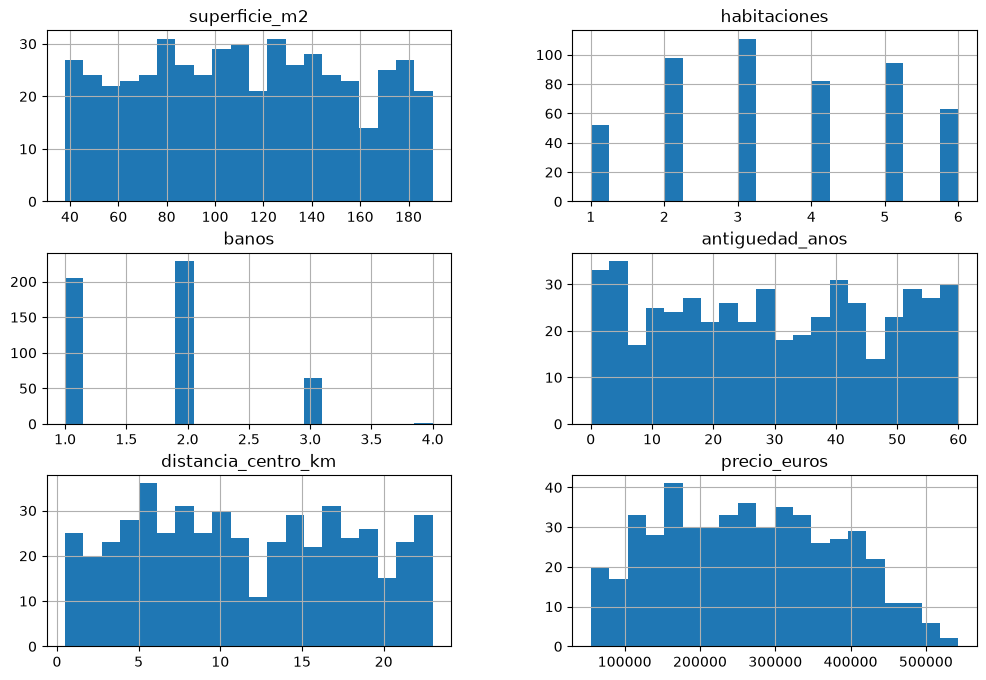

In [8]:
df.hist(figsize=(12,8), bins=20)

,superficie_m2,habitaciones,banos,antiguedad_anos,distancia_centro_km,precio_euros
superficie_m2,1.000000,0.859861,0.732887,0.084858,0.058840,0.905465
habitaciones,0.859861,1.000000,0.667388,0.104178,0.064905,0.806469
banos,0.732887,0.667388,1.000000,0.042433,0.019764,0.737736
antiguedad_anos,0.084858,0.104178,0.042433,1.000000,-0.041948,-0.101102
distancia_centro_km,0.058840,0.064905,0.019764,-0.041948,1.000000,-0.242572
precio_euros,0.905465,0.806469,0.737736,-0.101102,-0.242572,1.000000


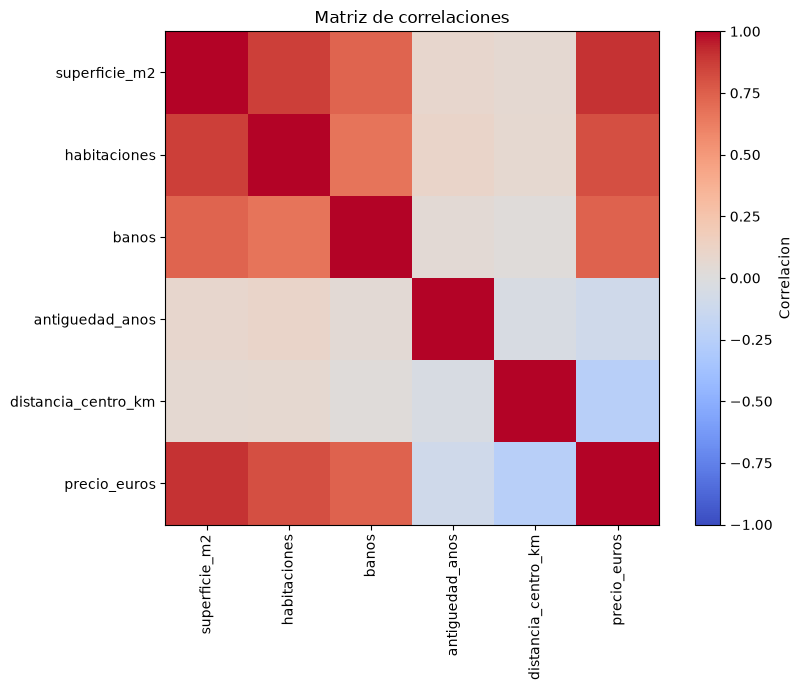

In [16]:
corr = df.select_dtypes(include="number").corr()
display(corr)

plt.figure(figsize=(9,7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.colorbar(label="Correlacion")
plt.title("Matriz de correlaciones")
plt.tight_layout()
plt.show()

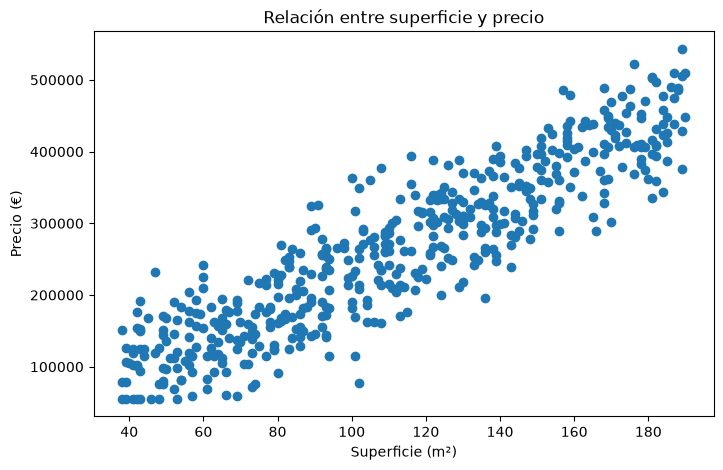

In [17]:
plt.figure(figsize=(8, 5))
# TODO: scatter superficie_m2 vs precio_euros
plt.scatter(df["superficie_m2"], df["precio_euros"])
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio (€)")
plt.title("Relación entre superficie y precio")
plt.show()

**Responde:** ¿relación positiva o negativa? ¿Parece lineal? ¿Qué otras variables influyen?

**Respuesta:** ...

## Parte 2 - Preparación y división
### Ejercicio 4. Separar X e y
No incluyas `vivienda_id` ni `precio_euros` en `X`.

In [24]:
'''
caracteristicas = [
    "superficie_m2", "habitaciones", "banos",
    "antiguedad_anos", "distancia_centro_km"
]
display(df[caracteristicas])
'''

# TODO: crear X eliminando las columnas que no son características
X = df.drop(columns=["vivienda_id", "precio_euros"])

# TODO: crear y con precio_euros
y = df["precio_euros"]

# TODO: mostrar dimensiones de X e y
display(X.head())
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

,superficie_m2,habitaciones,banos,antiguedad_anos,distancia_centro_km
0,168,4,3,21,17.6
1,65,3,2,55,15.8
2,42,2,1,34,7.6
3,135,5,3,43,15.5
4,93,5,1,10,20.3


Dimensiones de X: (500, 5)
Dimensiones de y: (500,)


**Responde:** ¿Por qué excluimos el identificador?

**Respuesta:** ...

### Ejercicio 5. Dividir 60 % / 20 % / 20 %
Usa `train_test_split` dos veces, `random_state=42`. No estratifiques directamente por el precio continuo.

In [ ]:
rom sklearn.model_selection import train_test_split

# TODO: separar X_train, X_temp, y_train, y_temp (40 % temp)

X_train, X_temp, y_train, y_temp = train_test_split(

X,
y,
test_size=0.4, #será X_train e y_train
random_state= 42
#stratify=y # NOOOOOO, SOLO sirve con categorías
)

# TODO: separar X_val, X_test, y_val, y_test (50 % de temporal para validación)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42
)
for grupo, a , b in[
    ('Train', X_train, y_train),
    ('Validation', X_val, y_val),
    ('Test', X_test, y_test)
]:
    print(grupo, a.shape, b.shape)
# TODO: imprimir dimensiones de los tres conjuntos

**Responde:** ¿Cuántas viviendas hay en cada conjunto? ¿Por qué dos divisiones? ¿Para qué se reserva test?

**Respuesta:** ...

## Parte 3 - Regresión lineal simple
### Ejercicio 6. Seleccionar superficie
Prepara `X_train_simple` y `X_val_simple` como DataFrames de una columna.

In [ ]:
# TODO: crear X_train_simple
# TODO: crear X_val_simple
# TODO: comprobar shape de ambos

**Responde:** ¿Por qué usamos dobles corchetes para una sola columna?

**Respuesta:** ...

### Ejercicio 7. Entrenar e interpretar la recta
Entrena `modelo_simple` y consulta `intercept_` y `coef_`. Escribe la ecuación `ŷ = b0 + b1·x`.

In [ ]:
from sklearn.linear_model import LinearRegression

modelo_simple = LinearRegression()
# TODO: entrenar usando X_train_simple e y_train
# TODO: imprimir intercepto y pendiente

**Responde:** intercepto, pendiente, signo y cambio estimado por m². ¿Tiene sentido físico una vivienda de 0 m²?

**Respuesta:** ...

### Ejercicio 8. Dibujar la recta
Representa los puntos de **entrenamiento** y la recta estimada. Puedes utilizar `np.linspace()` y un DataFrame con la columna `superficie_m2`.

In [ ]:
# TODO: crear un rango de superficies con np.linspace
# TODO: convertirlo a DataFrame y obtener predicciones
plt.figure(figsize=(8, 5))
# TODO: dibujar scatter de entrenamiento y línea del modelo
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio (€)")
plt.title("Regresión lineal simple")
plt.legend()
plt.show()

**Responde:** ¿Pasa la recta por todos los puntos? ¿Qué representa la distancia vertical entre un punto y la recta?

**Respuesta:** ...

### Ejercicio 9. Predecir una vivienda de 90 m²
Utiliza `predict()` con un DataFrame que tenga el nombre de columna correcto.

In [ ]:
nueva_vivienda = pd.DataFrame({"superficie_m2": [90]})
# TODO: predecir e imprimir precio estimado

**Responde:** ¿Qué precio predice? ¿Por qué no debe interpretarse como precio exacto? ¿Qué información falta?

**Respuesta:** ...

## Parte 4 - Regresión lineal múltiple
### Ejercicio 10. Construir y entrenar pipeline
Usa `SimpleImputer(strategy="median")` seguido de `LinearRegression()` y entrena únicamente con `X_train`, `y_train`.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

modelo_multiple = Pipeline([
    # TODO: paso llamado "imputer"
    # TODO: paso llamado "regresion"
])
# TODO: entrenar modelo_multiple

**Responde:** ¿Por qué la imputación debe ajustarse exclusivamente con entrenamiento?

**Respuesta:** ...

### Ejercicio 11. Interpretar los coeficientes
Accede a `modelo_multiple.named_steps["regresion"]` y crea una tabla con nombres y coeficientes.

In [ ]:
# TODO: recuperar el estimador de regresión del pipeline
# TODO: crear DataFrame con columnas "Caracteristica" y "Coeficiente"
# TODO: mostrar la tabla

**Responde:** ¿Qué coeficientes son positivos/negativos? Interpreta antigüedad y distancia al centro, manteniendo las demás variables constantes. ¿Se pueden comparar coeficientes de distintas unidades directamente?

**Respuesta:** ...

### Ejercicio 12. Predecir una vivienda con cinco características
Vivienda: 90 m², 3 habitaciones, 2 baños, 10 años y 5 km al centro. Compara con el modelo simple.

In [ ]:
vivienda_ejemplo = pd.DataFrame([{
    "superficie_m2": 90,
    "habitaciones": 3,
    "banos": 2,
    "antiguedad_anos": 10,
    "distancia_centro_km": 5
}])
# TODO: predecir con modelo_multiple
# TODO: comparar con predicción de modelo_simple para 90 m²

**Responde:** ¿Por qué pueden ser diferentes las predicciones? ¿Cuál usa más información?

**Respuesta:** ...

## Parte 5 - Evaluación y comparación
### Ejercicio 13. Predicciones en validación
Crea `predicciones_simple` y `predicciones_multiple` sobre **el mismo conjunto de validación**. Construye una tabla con precio real y ambas predicciones.

In [ ]:
# TODO: predicciones_simple = ...
# TODO: predicciones_multiple = ...
# TODO: DataFrame comparativo con real, simple y múltiple; mostrar 10 filas

### Ejercicio 14. Métricas MAE, MSE, RMSE y R²
Calcula las cuatro métricas para ambos modelos y preséntalas en una tabla.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# TODO: calcular MAE, MSE, RMSE = sqrt(MSE) y R² para modelo simple
# TODO: repetir para modelo múltiple
# TODO: mostrar DataFrame comparativo de métricas

**Responde:** ¿Cuál obtiene menor MAE/RMSE y mayor R²? ¿Qué significa el MAE en euros? ¿Por qué R² no es accuracy? ¿Qué modelo elegirías?

**Respuesta:** ...

### Ejercicio 15. Valores reales frente a predichos
Dibuja **dos gráficos** (uno por modelo) con precio real en X y predicho en Y. Añade la diagonal `ŷ = y` con los mismos límites para ambos ejes.

In [ ]:
# TODO: gráfico de modelo simple con diagonal de predicción perfecta
# TODO: gráfico de modelo múltiple con diagonal de predicción perfecta

**Responde:** ¿Cuál concentra los puntos más cerca de la diagonal? ¿Qué indica un punto alejado? ¿Qué significa que el precio predicho sea mayor que el real?

**Respuesta:** ...

### Ejercicio 16. Análisis de residuos
Calcula `residuos = y_val - predicciones_multiple` y representa residuos frente a precios predichos. Incluye línea horizontal en cero.

In [ ]:
# TODO: calcular residuos del modelo múltiple
plt.figure(figsize=(8, 5))
# TODO: scatter de predicciones_multiple vs residuos
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Precio predicho (€)")
plt.ylabel("Residuo (€)")
plt.title("Residuos de la regresión múltiple")
plt.show()

**Responde:** ¿Hay residuos positivos y negativos? ¿Se aprecia algún patrón? ¿Hay errores grandes? ¿Qué sugeriría una curva? ¿Qué aporta este gráfico respecto a las métricas?

**Respuesta:** ...

## Parte 6 - Conclusiones
### Ejercicio 17. Interpretación de resultados hipotéticos

| Métrica | Modelo A | Modelo B |
|---|---:|---:|
| MAE | 28.000 € | 16.000 € |
| RMSE | 38.000 € | 23.000 € |
| R² | 0,72 | 0,89 |

**Responde:** ¿Cuál tiene menor error? ¿Cuál elegirías y por qué? ¿Qué otras comprobaciones harías antes de usarlo en una aplicación real?

**Respuesta:** ...